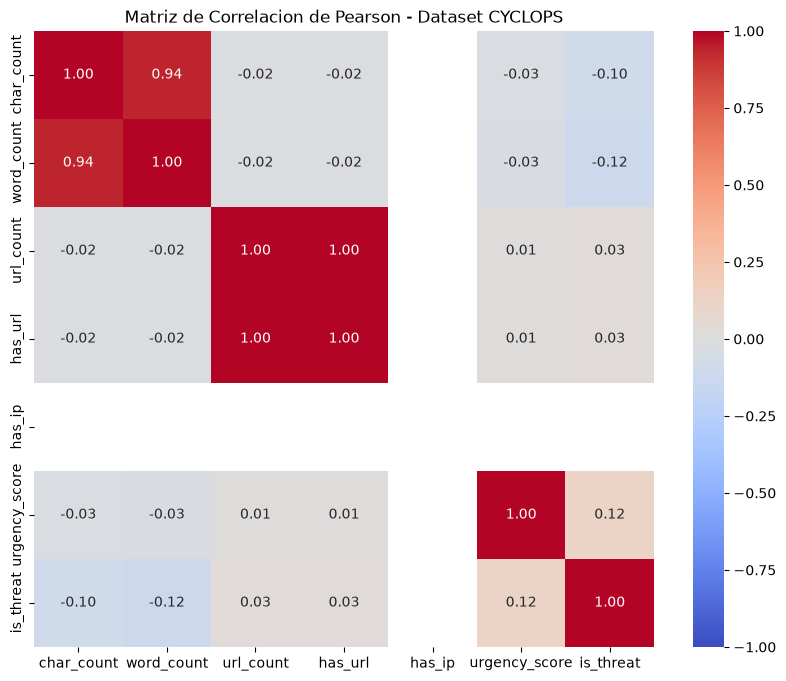

Correlation Results:
1. url_count (0.0312) + word_count (-0.1220) -> url_density: 0.0296
2. urgency_score (0.1235) + word_count (-0.1220) -> urgency_density: 0.0134


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Load the Clean Dataset
df= pd.read_csv('../data/processed/clean_dataset.csv')


# Calculation of the Correlation Matrix For the Numerical Columns
numeric_cols = [
    'char_count',
    'word_count',
    'url_count',
    'has_url',
    'has_ip',
    'urgency_score',
    'is_threat',
]
correlation_matrix = df[numeric_cols].corr(method='pearson')


# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlacion de Pearson - Dataset CYCLOPS')
plt.show()


# Mathematical Validation of the Composite Variable
df['url_density'] = df['url_count'] / (df['word_count'] + 1)
df['urgency_density'] = df['urgency_score'] / (df['word_count'] + 1)
df['ip_exposure_score'] = df['has_ip'] * df['url_count']


# Comparison With the Target Variable 
corr_url = df['url_count'].corr(df['is_threat'])
corr_word = df['word_count'].corr(df['is_threat'])
corr_url_density = df['url_density'].corr(df['is_threat'])

# Comparison With the Target Variable 
corr_urgency = df['urgency_score'].corr(df['is_threat'])
corr_word = df['word_count'].corr(df['is_threat'])
corr_urg_density = df['urgency_density'].corr(df['is_threat'])


# Print the Correlation Results
print("Correlation Results:")
print(f'1. url_count ({corr_url:.4f}) + word_count ({corr_word:.4f}) -> url_density: {corr_url_density:.4f}')
print(f'2. urgency_score ({corr_urgency:.4f}) + word_count ({corr_word:.4f}) -> urgency_density: {corr_urg_density:.4f}')

